# Step 0 – Data Preparation and Exploratory Data Analysis
**Student:** Indrajith KTN 224078X

**AI use declaration:** This notebook's code was generated with the help of Claude (Anthropic)
and reviewed / run by the student.

**What this notebook does**
1. Loads the raw Sri Lankan bird records (about 1.55 million rows).
2. Cleans the data (dates, missing values, duplicates).
3. Aggregates it to one row per **district x year x month** with the target `species_richness`
   (number of different bird species recorded) and the environmental features.
4. Saves `data/processed/bird_monthly_data.csv` (used by all later notebooks and the dashboard).
5. Shows the key EDA plots.

**Data source:** https://huggingface.co/datasets/DilushaChandrasiri/SriLanka-Bird-Diversity-Dataset - source of SriLanka-Bird-Diversity-Dataset.csv

Folder needed: `data/raw/SriLanka-Bird-Diversity-Dataset.csv`

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

RAW_PATH = "../data/raw/SriLanka-Bird-Diversity-Dataset.csv"
OUT_PATH = "../data/processed/bird_monthly_data.csv"

## 1. Load the raw data

In [2]:
df = pd.read_csv(RAW_PATH, low_memory=False)
print("Raw shape:", df.shape)
df.head()

Raw shape: (1552048, 24)


,index,verbatimScientificName,stateProvince,individualCount,decimalLatitude,decimalLongitude,eventDate,avg_rad,NDVI_raw,LandCover_Class,...,Sulfate_Mass,Sea_Salt_Mass,Total_Aerosol_Extinction,temp_mean,rainfall,wind_mean,humid_mean,shortwave_radiation,lka_general_2020,NDVI
0,0,Anarhynchus alexandrinus,Mannar,8.0,9.058512,79.85502,2021-01-06,0.66,3792.0,10,...,3.372161e-09,3.725563e-08,0.175115,26.58,15.17,1.31,85.53,17.65,2.805795,0.3792
1,2,Hirundo rustica,Colombo,10.0,6.866285,79.93144,2024-12-23,10.16,7045.0,13,...,4.424376e-09,3.249729e-08,0.198127,26.21,0.25,2.51,84.30,20.49,8.917330,0.7045
2,6,Corvus macrorhynchos,Matara,2.0,5.983496,80.52548,2024-10-12,1.26,6989.0,10,...,7.456183e-10,5.362027e-08,0.131458,26.91,14.47,5.18,83.81,15.67,2.768103,0.6989
3,7,Dicrurus caerulescens,Matale,1.0,7.969125,80.75477,2021-11-20,0.37,8543.0,8,...,1.612494e-09,3.017664e-08,0.123156,25.30,2.54,2.98,89.54,21.99,3.339740,0.8543
4,8,Threskiornis melanocephalus,Jaffna,30.0,9.637712,79.95190,2019-03-25,0.52,4000.0,10,...,2.737918e-09,3.224930e-08,0.220155,29.67,0.00,4.65,63.33,24.53,3.209018,0.4000


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1552048 entries, 0 to 1552047
Data columns (total 24 columns):
 #   Column                    Non-Null Count    Dtype  
---  ------                    --------------    -----  
 0   index                     1552048 non-null  int64  
 1   verbatimScientificName    1552048 non-null  str    
 2   stateProvince             1552048 non-null  str    
 3   individualCount           1552048 non-null  float64
 4   decimalLatitude           1552048 non-null  float64
 5   decimalLongitude          1552048 non-null  float64
 6   eventDate                 1552048 non-null  str    
 7   avg_rad                   1552048 non-null  float64
 8   NDVI_raw                  1552048 non-null  float64
 9   LandCover_Class           1552048 non-null  int64  
 10  elevation_meters          1552048 non-null  int64  
 11  Carbon_Mass               1552048 non-null  float64
 12  Dust_Mass                 1552048 non-null  float64
 13  SO2_Mass                  1552048 non-

## 2. Missing values

In [4]:
missing = df.isnull().sum()
missing[missing > 0].sort_values(ascending=False)

Series([], dtype: int64)

## 3. Cleaning
- Convert `eventDate` to a date (invalid dates become missing).
- Drop rows with no date, species name or district (these cannot be used for the target).
- Drop exact duplicate rows.

In [5]:
rows_before = len(df)

df["eventDate"] = pd.to_datetime(df["eventDate"], errors="coerce")
df = df.dropna(subset=["eventDate", "verbatimScientificName", "stateProvince"])
print("Rows after dropping missing date/species/district:", len(df))

print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()

print(f"Rows: {rows_before:,} -> {len(df):,}")

Rows after dropping missing date/species/district: 1552048
Duplicates: 0
Rows: 1,552,048 -> 1,552,048


## 4. Time features

In [6]:
df["Year"] = df["eventDate"].dt.year
df["Month"] = df["eventDate"].dt.month
print("Years:", df["Year"].min(), "-", df["Year"].max(), "| Districts:", df["stateProvince"].nunique())

Years: 2014 - 2024 | Districts: 25


## 5. Aggregate to district x year x month
- `species_richness` = number of **different** species recorded
- `observation_count` = number of records (survey effort)
- environmental features = mean value of the records in that district-month

In [7]:
monthly_data = df.groupby(["stateProvince", "Year", "Month"]).agg(
    species_richness=("verbatimScientificName", "nunique"),
    observation_count=("verbatimScientificName", "count"),
    average_temperature=("temp_mean", "mean"),
    average_rainfall=("rainfall", "mean"),
    average_humidity=("humid_mean", "mean"),
    average_ndvi=("NDVI", "mean"),
    average_wind=("wind_mean", "mean"),
    average_elevation=("elevation_meters", "mean"),
    average_population_density=("lka_general_2020", "mean"),
    average_night_light=("avg_rad", "mean"),
).reset_index()

print("Monthly data shape:", monthly_data.shape)
monthly_data.head()

Monthly data shape: (2454, 13)


,stateProvince,Year,Month,species_richness,observation_count,average_temperature,average_rainfall,average_humidity,average_ndvi,average_wind,average_elevation,average_population_density,average_night_light
0,Ampara,2014,2,125,167,26.592994,0.468443,74.470838,0.532631,3.181257,3.005988,2.643937,0.439339
1,Ampara,2014,3,1,1,27.790000,0.000000,63.800000,0.539900,1.600000,5.000000,1.566867,0.346376
2,Ampara,2014,6,36,41,29.426341,0.510488,72.847805,0.494141,2.739756,5.609756,3.797562,1.234339
3,Ampara,2014,7,46,46,29.790000,0.490000,71.750000,0.444400,2.080000,4.000000,3.116725,2.162765
4,Ampara,2015,3,68,136,28.350000,3.570000,79.250000,0.728900,3.590000,25.000000,0.000000,0.188859


In [8]:
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)
monthly_data.to_csv(OUT_PATH, index=False)
print("Saved:", OUT_PATH)

Saved: ../data/processed/bird_monthly_data.csv


## 6. EDA plots

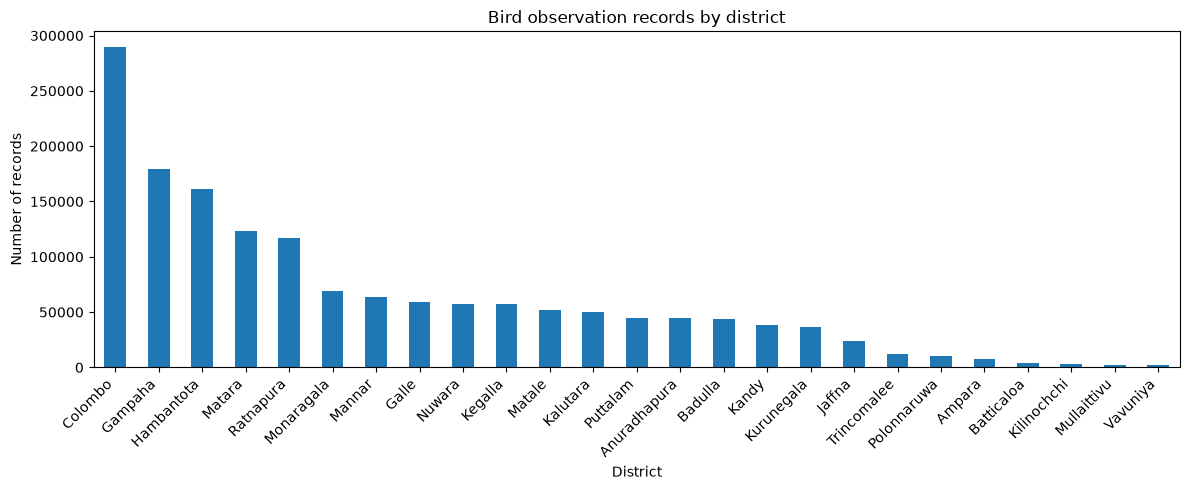

In [9]:
plt.figure(figsize=(12, 5))
df["stateProvince"].value_counts().plot(kind="bar")
plt.title("Bird observation records by district")
plt.xlabel("District"); plt.ylabel("Number of records")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

*What it shows:* records are very unevenly spread. Some districts have far more records than others,
which affects recorded richness (survey effort).

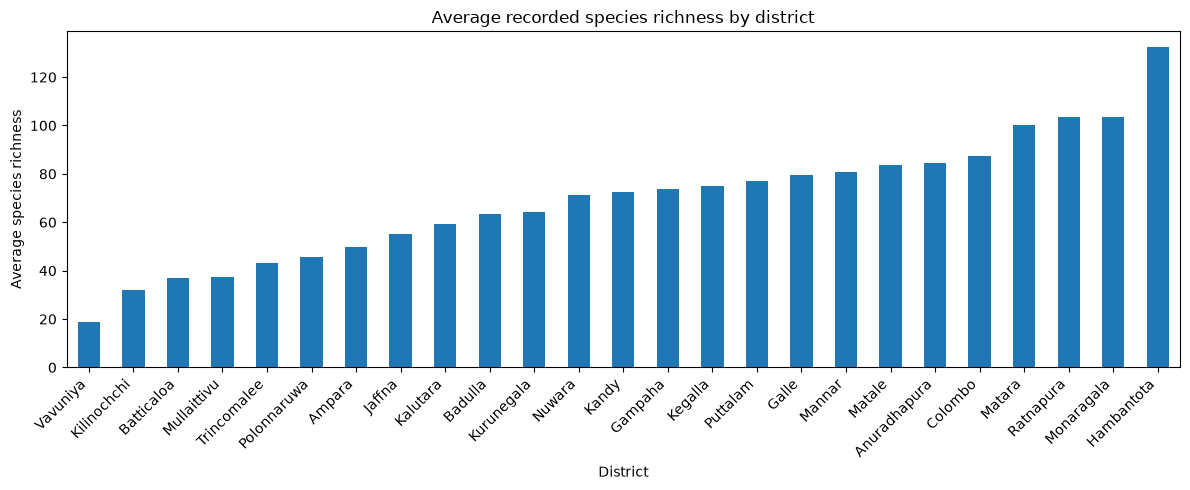

In [10]:
district_richness = monthly_data.groupby("stateProvince")["species_richness"].mean().sort_values()
plt.figure(figsize=(12, 5))
district_richness.plot(kind="bar")
plt.title("Average recorded species richness by district")
plt.xlabel("District"); plt.ylabel("Average species richness")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

*What it shows:* district is a strong factor, since districts differ in habitat and in how much they are visited.

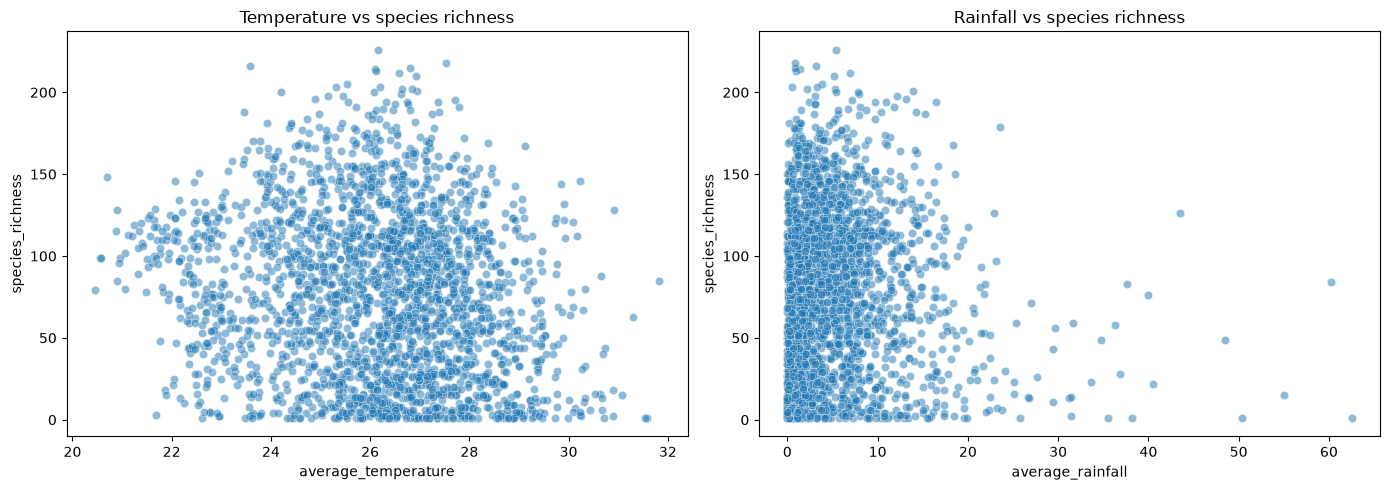

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=monthly_data, x="average_temperature", y="species_richness", ax=axes[0], alpha=0.5)
axes[0].set_title("Temperature vs species richness")
sns.scatterplot(data=monthly_data, x="average_rainfall", y="species_richness", ax=axes[1], alpha=0.5)
axes[1].set_title("Rainfall vs species richness")
plt.tight_layout(); plt.show()

*What it shows:* no clear straight-line relationship with temperature or rainfall alone,
so simple linear models are expected to have limited accuracy.

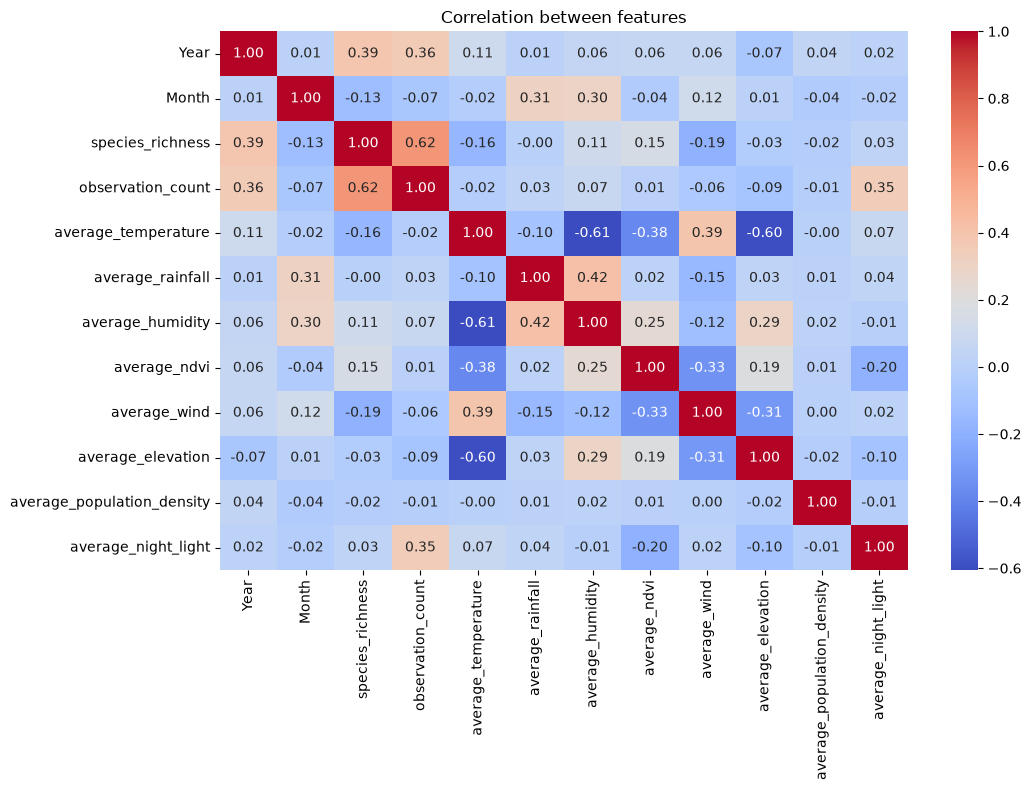

In [12]:
plt.figure(figsize=(11, 8))
sns.heatmap(monthly_data.select_dtypes(include="number").corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation between features")
plt.tight_layout(); plt.show()

*What it shows:* `species_richness` is strongly correlated with `observation_count` (survey effort), much more than with
any environmental variable. This is why `observation_count` is excluded from the main models and studied separately in Step 1.

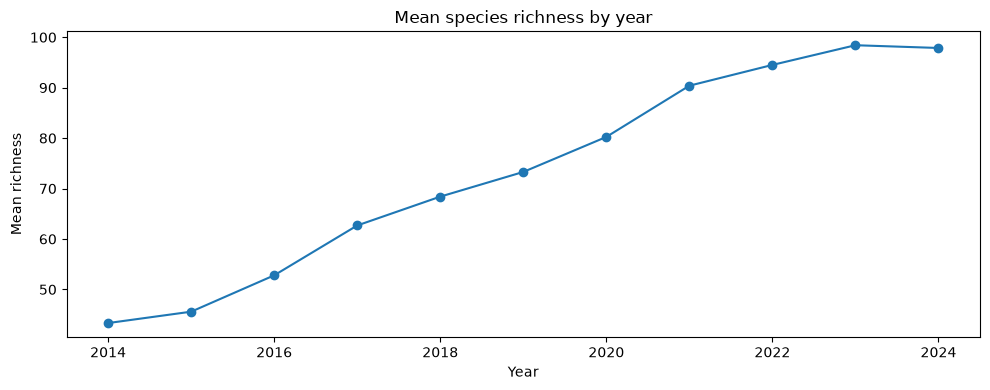

In [13]:
monthly_data.groupby("Year")["species_richness"].mean().plot(marker="o", figsize=(10, 4),
                                                             title="Mean species richness by year")
plt.ylabel("Mean richness"); plt.tight_layout(); plt.show()